# Mini-projet : tableau de bord « Risque d'accidents du travail par secteur »


**Données** : taux collectifs de cotisation *Accidents du travail / Maladies professionnelles* (AT/MP) par activité, publiés en open data (Licence Ouverte) : https://github.com/betagouv/taux-collectifs-cotisation-atmp

⚠️ **À savoir** : ces taux sont des **taux de cotisation** par activité. Ils servent d'indicateur du niveau de risque d'un secteur, mais ce **n'est pas** un nombre d'accidents. Pense à le préciser dans tes conclusions.





## Étape 1 — Importer les outils
`pandas` sert à manipuler les tableaux de données, `matplotlib` à faire les graphiques.

In [ ]:
import unicodedata

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 60)
plt.rcParams["figure.dpi"] = 110

## Étape 2 — Charger les données
On charge 3 années (2016, 2017, 2018) directement depuis GitHub, puis on les **empile** dans un seul tableau en ajoutant une colonne `annee`.

In [ ]:
URL_BASE = "https://raw.githubusercontent.com/betagouv/taux-collectifs-cotisation-atmp/master/"
ANNEES = [2016, 2017, 2018]

tableaux = []
for annee in ANNEES:
    t = pd.read_csv(f"{URL_BASE}taux-{annee}.csv", dtype=str)   # dtype=str : on garde tout en texte, on nettoie ensuite
    t["annee"] = annee
    tableaux.append(t)

brut = pd.concat(tableaux, ignore_index=True)
print(brut.shape)
brut.head()

(721, 6)


,Nature du risque,Code risque,Taux net,Taux commun quel que soit effectif ?,Catégorie,annee
0,"Fabrication de fonte, d'acier, d'articles ou tubes en fo...",27.1ZF,"6,4",NaN,industries de la métallurgie,2016
1,Métallurgie des métaux non ferreux et précieux. Laminage...,27.4CH,"4,3",NaN,industries de la métallurgie,2016
2,Fonderie des métaux légers ou non ferreux.,27.5EB,"5,8",NaN,industries de la métallurgie,2016
3,"Construction métallique, fabrication de charpentes ; fou...",28.1AD,"5,1",NaN,industries de la métallurgie,2016
4,"Fabrication d'articles, de meubles et menuiseries, de fû...",28.1CB,"3,3",NaN,industries de la métallurgie,2016


## Étape 3 — Explorer (toujours avant de nettoyer !)
Questions à te poser : combien de lignes ? quelles colonnes ? des valeurs manquantes ? des formats bizarres ?

In [ ]:
print(brut.columns.tolist())
print()
print("Valeurs manquantes par colonne :")
print(brut.isna().sum())
print()
print("Lignes par année :")
print(brut["annee"].value_counts().sort_index())

['Nature du risque', 'Code risque', 'Taux net', 'Taux commun quel que soit effectif\xa0?', 'Catégorie', 'annee']

Valeurs manquantes par colonne :
Nature du risque                          0
Code risque                               0
Taux net                                  0
Taux commun quel que soit effectif ?    591
Catégorie                                 0
annee                                     0
dtype: int64

Lignes par année :
annee
2016    286
2017    218
2018    217
Name: count, dtype: int64


## Étape 4 — Nettoyer
Problèmes à corriger :
1. Les noms de colonnes sont longs (et l'un contient une espace insécable) → on les renomme.
2. `taux_net` est du **texte avec une virgule** (`"6,4"`) → on le convertit en nombre (`6.4`).
3. Les noms de secteurs contiennent des retours à la ligne et des espaces en trop → on les normalise.
4. L'orthographe d'un même secteur change parfois d'une année à l'autre (accents) → on crée une **clé commune sans accents** pour pouvoir comparer les années.

In [ ]:
df = brut.copy()

# 1) Renommer les colonnes (la 4e colonne a un nom compliqué, on la renomme par sa position)
df = df.rename(columns={
    "Nature du risque": "activite",
    "Code risque": "code",
    "Taux net": "taux_net",
    "Catégorie": "secteur",
})
df = df.rename(columns={df.columns[3]: "taux_commun"})

# 2) Convertir le taux en nombre
df["taux_net"] = df["taux_net"].str.replace(",", ".", regex=False).astype(float)

# 3) Normaliser les textes
for col in ["activite", "secteur"]:
    df[col] = df[col].str.replace(r"\s+", " ", regex=True).str.strip()
df["secteur"] = df["secteur"].str.upper()


# 4) Clé de regroupement SANS accents : d'une année à l'autre, l'orthographe change parfois
#    (ex. « ÉLECTRICITE » / « ELECTRICITE »). Sans clé commune, Python croirait à deux secteurs différents.
def sans_accents(texte):
    return "".join(c for c in unicodedata.normalize("NFD", texte) if unicodedata.category(c) != "Mn")


df["cle_secteur"] = df["secteur"].map(sans_accents)


# 5) Nom court et unique par secteur pour les graphiques (on ajoute « … » seulement si le texte est coupé)
def court(texte, n):
    return texte if len(texte) <= n else texte[:n].rstrip() + "…"


dernier_nom = df.sort_values("annee").groupby("cle_secteur")["secteur"].last()   # on garde l'orthographe la plus récente
df["secteur_court"] = (df["cle_secteur"].map(dernier_nom).str.capitalize()
                       .str.replace(r"\b(ii|i)\b", lambda m: m.group(1).upper(), regex=True)
                       .map(lambda t: court(t, 38)))

df = df.drop(columns=["taux_commun"])
df.head()

,activite,code,taux_net,secteur,annee,cle_secteur,secteur_court
0,"Fabrication de fonte, d'acier, d'articles ou tubes en fo...",27.1ZF,6.4,INDUSTRIES DE LA MÉTALLURGIE,2016,INDUSTRIES DE LA METALLURGIE,Industries de la métallurgie
1,Métallurgie des métaux non ferreux et précieux. Laminage...,27.4CH,4.3,INDUSTRIES DE LA MÉTALLURGIE,2016,INDUSTRIES DE LA METALLURGIE,Industries de la métallurgie
2,Fonderie des métaux légers ou non ferreux.,27.5EB,5.8,INDUSTRIES DE LA MÉTALLURGIE,2016,INDUSTRIES DE LA METALLURGIE,Industries de la métallurgie
3,"Construction métallique, fabrication de charpentes ; fou...",28.1AD,5.1,INDUSTRIES DE LA MÉTALLURGIE,2016,INDUSTRIES DE LA METALLURGIE,Industries de la métallurgie
4,"Fabrication d'articles, de meubles et menuiseries, de fû...",28.1CB,3.3,INDUSTRIES DE LA MÉTALLURGIE,2016,INDUSTRIES DE LA METALLURGIE,Industries de la métallurgie


### Vérifications de qualité (ce que fait un bon analyste avant de publier un chiffre)

In [ ]:
# Le taux est bien un nombre ? Y a-t-il des valeurs extrêmes ?
print(df["taux_net"].describe().round(2))
print()
# Les secteurs sont-ils présents chaque année ? (on utilise la clé sans accents)
presence = df.groupby("cle_secteur")["annee"].nunique()
secteurs_stables = presence[presence == len(ANNEES)].index
print(f"Secteurs présents les {len(ANNEES)} années : {len(secteurs_stables)} sur {len(presence)}")
print()
print("Secteurs qui n'existent pas toutes les années (à ne pas comparer dans le temps) :")
for cle, n in presence[presence < len(ANNEES)].items():
    annees = [int(a) for a in sorted(df[df.cle_secteur == cle]["annee"].unique())]
    print(f"  - {cle[:70]}… (années : {annees})")

count    721.0
mean       3.8
std        9.8
min        0.0
25%        1.7
50%        2.6
75%        4.0
max      201.0
Name: taux_net, dtype: float64

Secteurs présents les 3 années : 10 sur 12

Secteurs qui n'existent pas toutes les années (à ne pas comparer dans le temps) :
  - CATEGORIES DE PERSONNELS VISES PAR L'ARRETE PREVU A L'ARTICLE D. 242-6… (années : [2016, 2017])
  - SALARIES VISES A L'ARTICLE 1ER (III) DE L'ARRETE DU 17 OCTOBRE 1995 RE… (années : [2018])


### Repérer les valeurs aberrantes (très important !)
Regarde le `max` du tableau ci-dessus : certaines valeurs sont **très** supérieures aux autres. Une moyenne est très sensible aux valeurs extrêmes : elles peuvent fausser tes conclusions. Regardons-les.

In [ ]:
print("Les 8 taux les plus élevés :")
df.nlargest(8, "taux_net")[["annee", "activite", "taux_net"]].assign(activite=lambda d: d["activite"].str.slice(0, 70))

Les 8 taux les plus élevés :


,annee,activite,taux_net
684,2018,Elèves et étudiants des établissements publics et privés...,201.0
190,2016,Fabrication de produits en fibre-ciment.,103.8
418,2017,Fabrication de produits en fibre-ciment.,95.0
636,2018,Fabrication de produits en fibre-ciment.,81.7
90,2016,"Ouvriers dockers maritimes intermittents, soumis au régi...",35.0
344,2017,"Ouvriers dockers maritimes intermittents, soumis au régi...",35.0
562,2018,"Ouvriers dockers maritimes intermittents, soumis au régi...",35.0
683,2018,Elèves et étudiants des établissements publics ou privés...,23.0


Ce sont des **cas particuliers** (ex. élèves et étudiants, dockers intermittents) dont le taux n'est pas comparable à celui des autres activités. Décision d'analyste, **à documenter** : on les met de côté pour les moyennes et les graphiques (seuil de 30 %), mais on garde la liste pour la transparence.

In [ ]:
SEUIL = 30
aberrantes = df[df["taux_net"] > SEUIL]
df_ok = df[df["taux_net"] <= SEUIL].copy()

print(f"{len(aberrantes)} lignes mises de côté (taux > {SEUIL} %) sur {len(df)}.")
aberrantes[["annee", "activite", "taux_net"]].assign(activite=lambda d: d["activite"].str.slice(0, 70))

7 lignes mises de côté (taux > 30 %) sur 721.


,annee,activite,taux_net
90,2016,"Ouvriers dockers maritimes intermittents, soumis au régi...",35.0
190,2016,Fabrication de produits en fibre-ciment.,103.8
344,2017,"Ouvriers dockers maritimes intermittents, soumis au régi...",35.0
418,2017,Fabrication de produits en fibre-ciment.,95.0
562,2018,"Ouvriers dockers maritimes intermittents, soumis au régi...",35.0
636,2018,Fabrication de produits en fibre-ciment.,81.7
684,2018,Elèves et étudiants des établissements publics et privés...,201.0


## Étape 5 — Calculer les indicateurs (KPI)
Un **KPI** est un chiffre clé qui résume la situation. Ici : le nombre d'activités suivies, le taux moyen, le taux médian et le taux maximum, par année (hors valeurs aberrantes). On ajoute aussi la moyenne *avec* les valeurs aberrantes pour voir leur effet.

In [ ]:
kpi = df_ok.groupby("annee")["taux_net"].agg(
    nb_activites="count",
    taux_moyen="mean",
    taux_median="median",
    taux_max="max",
).round(2)

kpi["taux_moyen_avec_aberrantes"] = df.groupby("annee")["taux_net"].mean().round(2)
kpi

,nb_activites,taux_moyen,taux_median,taux_max,taux_moyen_avec_aberrantes
annee,,,,,
2016,284,3.18,2.7,10.0,3.64
2017,216,2.90,2.5,10.2,3.47
2018,214,2.92,2.5,23.0,4.34


## Étape 6 — Construire le tableau de bord (4 graphiques)
1. Taux moyen et médian par année
2. Les 10 secteurs au taux moyen le plus élevé (dernière année)
3. Évolution du taux moyen des 5 secteurs les plus exposés
4. Les 10 activités au taux le plus élevé (dernière année)

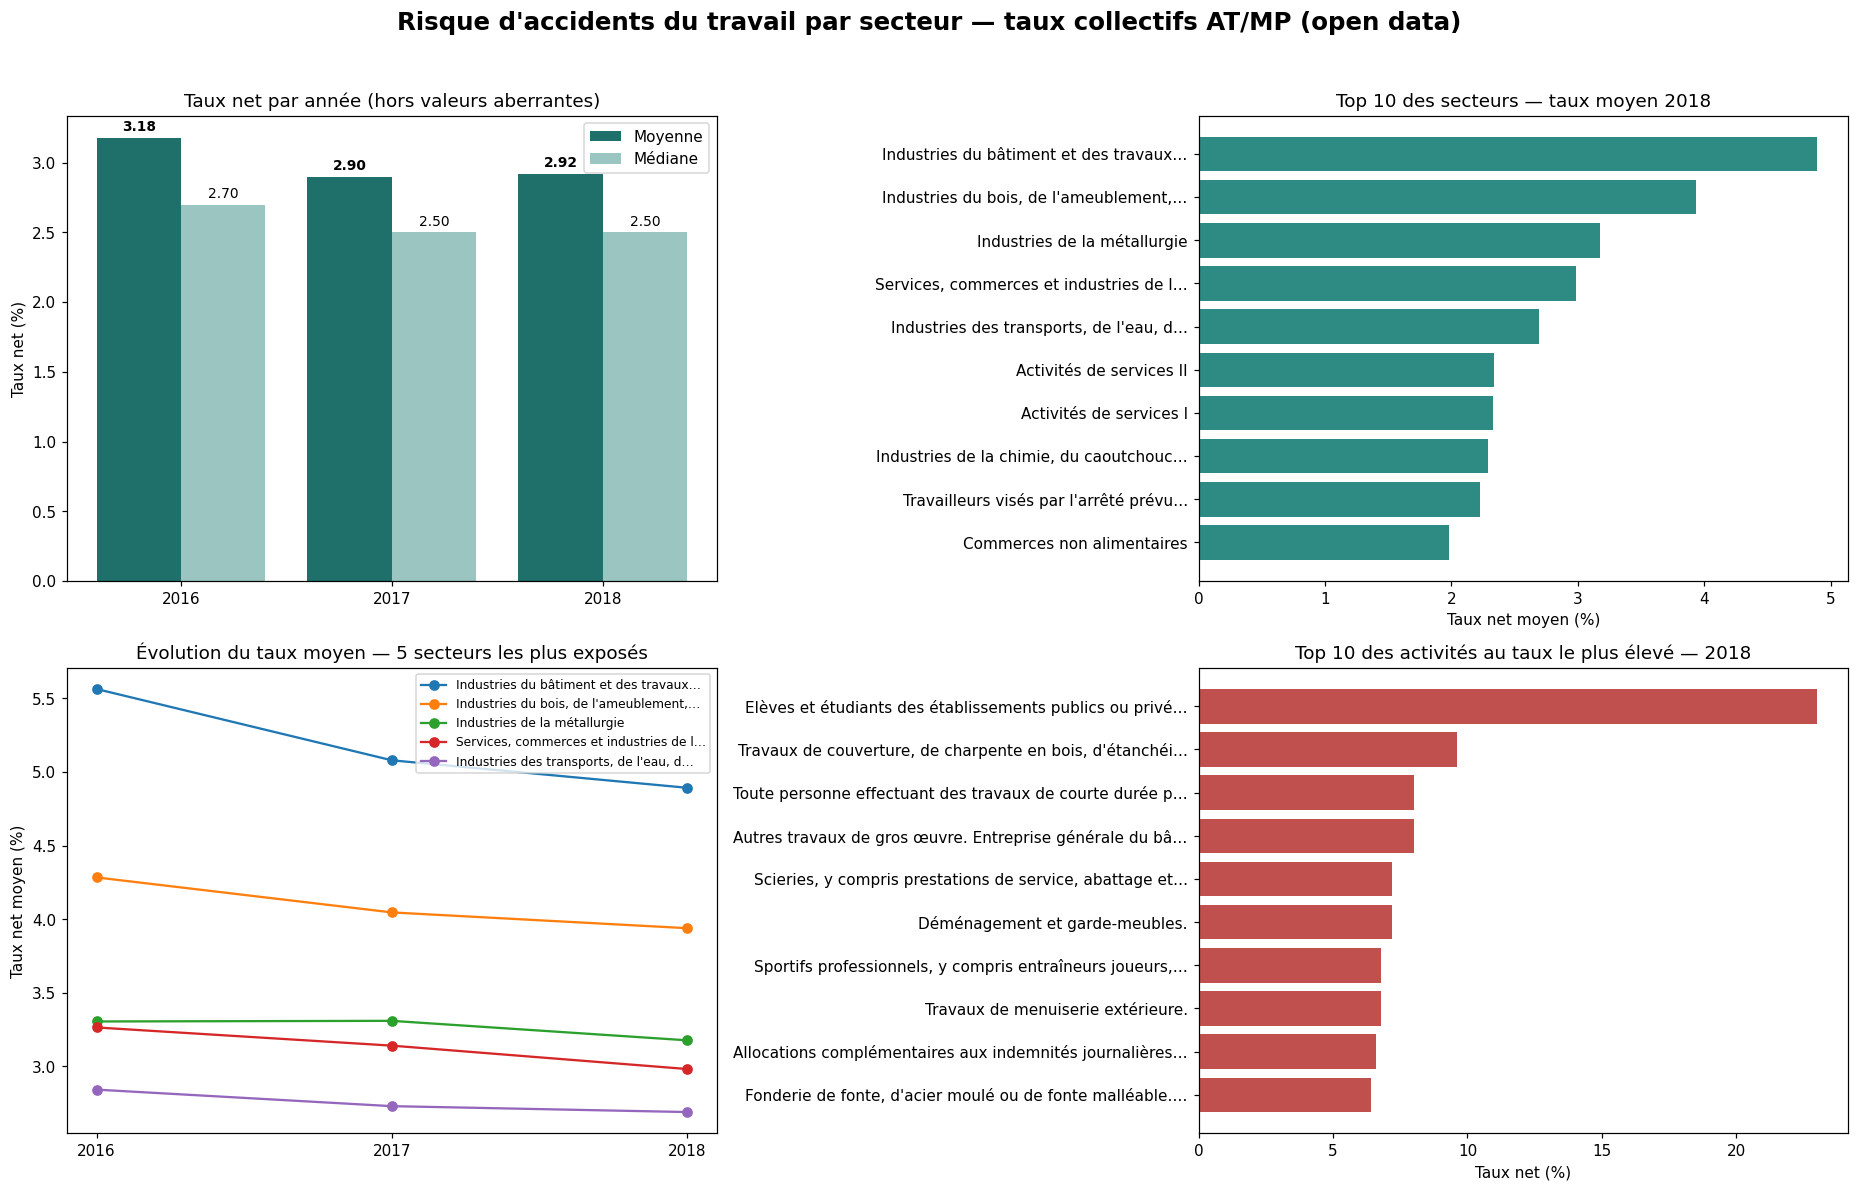

In [ ]:
derniere = max(ANNEES)

fig, axes = plt.subplots(2, 2, figsize=(17, 11))
fig.suptitle("Risque d'accidents du travail par secteur — taux collectifs AT/MP (open data)",
             fontsize=16, fontweight="bold")

# 1) Taux moyen et médian par année
ax = axes[0, 0]
x = range(len(kpi))
ax.bar([i - 0.2 for i in x], kpi["taux_moyen"], width=0.4, color="#1F6F6B", label="Moyenne")
ax.bar([i + 0.2 for i in x], kpi["taux_median"], width=0.4, color="#9BC5C1", label="Médiane")
for i, (m, med) in enumerate(zip(kpi["taux_moyen"], kpi["taux_median"])):
    ax.text(i - 0.2, m + 0.05, f"{m:.2f}", ha="center", fontsize=9, fontweight="bold")
    ax.text(i + 0.2, med + 0.05, f"{med:.2f}", ha="center", fontsize=9)
ax.set_xticks(list(x))
ax.set_xticklabels(kpi.index.astype(str))
ax.set_title("Taux net par année (hors valeurs aberrantes)")
ax.set_ylabel("Taux net (%)")
ax.legend()

# 2) Top 10 secteurs (taux moyen, dernière année)
ax = axes[0, 1]
top_secteurs = (df_ok[df_ok.annee == derniere].groupby("secteur_court")["taux_net"].mean()
                .sort_values().tail(10))
ax.barh(top_secteurs.index, top_secteurs.values, color="#2E8B84")
ax.set_title(f"Top 10 des secteurs — taux moyen {derniere}")
ax.set_xlabel("Taux net moyen (%)")

# 3) Évolution des 5 secteurs les plus exposés
ax = axes[1, 0]
stables = df_ok[df_ok.cle_secteur.isin(secteurs_stables)]   # évolution : seulement les secteurs présents toutes les années
pivot = stables.pivot_table(index="annee", columns="secteur_court", values="taux_net", aggfunc="mean")
top5 = pivot.loc[derniere].sort_values(ascending=False).head(5).index
for s in top5:
    ax.plot(pivot.index, pivot[s], marker="o", label=s)
ax.set_xticks(ANNEES)
ax.set_title("Évolution du taux moyen — 5 secteurs les plus exposés")
ax.set_ylabel("Taux net moyen (%)")
ax.legend(fontsize=8)

# 4) Top 10 activités (dernière année)
ax = axes[1, 1]
top_act = df_ok[df_ok.annee == derniere].nlargest(10, "taux_net").sort_values("taux_net")
etiquettes = top_act["activite"].map(lambda t: court(t, 55))
ax.barh(etiquettes, top_act["taux_net"], color="#C0504D")
ax.set_title(f"Top 10 des activités au taux le plus élevé — {derniere}")
ax.set_xlabel("Taux net (%)")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Étape 7 — Rédiger les conclusions
Un tableau de bord sans phrase de conclusion n'est qu'un dessin. Le code ci-dessous génère automatiquement 3 constats chiffrés : **relis-les, vérifie-les sur les graphiques, puis reformule-les avec tes mots.**

In [ ]:
annee_debut, annee_fin = ANNEES[0], ANNEES[-1]
moy = kpi["taux_moyen"]
secteur_max = df_ok[df_ok.annee == annee_fin].groupby("secteur")["taux_net"].mean().idxmax()
activite_max = df_ok[df_ok.annee == annee_fin].nlargest(1, "taux_net").iloc[0]

print(f"1) Hors valeurs aberrantes, le taux net moyen est passé de {moy[annee_debut]:.2f} % en {annee_debut} à {moy[annee_fin]:.2f} % en {annee_fin}.")
print(f"2) En {annee_fin}, le secteur au taux moyen le plus élevé est : {secteur_max.capitalize()}.")
print(f"3) L'activité au taux le plus élevé en {annee_fin} : {activite_max['activite'][:90]}… ({activite_max['taux_net']} %).")
print()
print(f"Méthode : {len(aberrantes)} lignes au taux > {SEUIL} % ont été écartées (cas particuliers).")
print("Limite : ce sont des taux de cotisation par activité, pas des nombres d'accidents.")

1) Hors valeurs aberrantes, le taux net moyen est passé de 3.18 % en 2016 à 2.92 % en 2018.
2) En 2018, le secteur au taux moyen le plus élevé est : Industries du bâtiment et des travaux publics.
3) L'activité au taux le plus élevé en 2018 : Elèves et étudiants des établissements publics ou privés d'enseignement secondaire, supéri… (23.0 %).

Méthode : 7 lignes au taux > 30 % ont été écartées (cas particuliers).
Limite : ce sont des taux de cotisation par activité, pas des nombres d'accidents.


## Étape 8 — Exporter et publier
Sauvegarde le graphique et les données nettoyées, puis mets le projet sur GitHub avec un fichier `README.md` (objectif, données, méthode, résultats, captures).

In [ ]:
fig.savefig("dashboard_atmp.png", dpi=150, bbox_inches="tight")
df_ok.to_csv("atmp_nettoye.csv", index=False)
print("Fichiers créés : dashboard_atmp.png et atmp_nettoye.csv")

Fichiers créés : dashboard_atmp.png et atmp_nettoye.csv


In [12]:
from google.colab import files

fig.savefig("dashboard_atmp_3ans.png", dpi=150, bbox_inches="tight")
df_ok.to_csv("atmp_nettoye_3ans.csv", index=False)

files.download("dashboard_atmp_3ans.png")
files.download("atmp_nettoye_3ans.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>